=== Model Coefficients ===
MedInc: 1.0377
HouseAge: 0.2092
AveRooms: -0.5324
AveBedrms: 0.4811
Population: 0.0218
Intercept: 2.0719

=== Evaluation Metrics ===
R² Score: 0.5090
Mean Absolute Error (MAE): 0.5802
Mean Squared Error (MSE): 0.6434
Root Mean Squared Error (RMSE): 0.8021


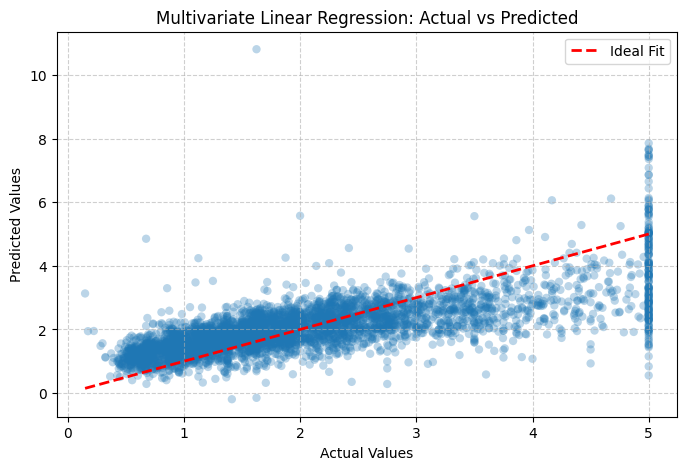

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

housing = fetch_california_housing(as_frame=True)
df = housing.frame

features = ["MedInc", "HouseAge", "AveRooms", "AveBedrms", "Population"]
X = df[features]
y = df["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LinearRegression()
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("=== Model Coefficients ===")
for feature, coef in zip(features, model.coef_):
    print(f"{feature}: {coef:.4f}")
print(f"Intercept: {model.intercept_:.4f}\n")

print("=== Evaluation Metrics ===")
print(f"R² Score: {r2:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")

plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.3, color="#1f77b4", edgecolor="none")
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "--r",
    linewidth=2,
    label="Ideal Fit",
)
plt.title("Multivariate Linear Regression: Actual vs Predicted")
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()